In [19]:
import torchvision 
from torchvision import transforms
from torch import nn
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)   
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)   


In [20]:
train_dataset[0]

(tensor([[[-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
           -1.0000, -1.0000, -1.000

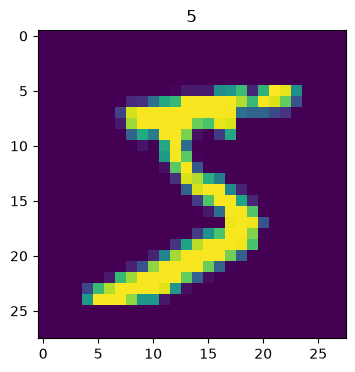

In [21]:
import matplotlib.pyplot as plt
import numpy as np

image, label = train_dataset[0]
image = np.transpose(image, (1, 2, 0))
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(label);

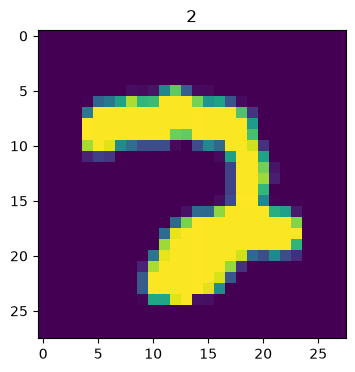

In [22]:
image, label = train_dataset[120]
image = np.transpose(image, (1, 2, 0))
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(label);

In [23]:
import torch
train_loader = torch.utils.data.DataLoader(
    dataset = train_dataset,
    batch_size = 30,
    shuffle = True
)

test_loader = torch.utils.data.DataLoader(
    dataset = test_dataset,
    batch_size = 30,
    shuffle = False
)

In [24]:
class_names = train_dataset.classes
class_names

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [25]:
#check shapes
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

img, label = next(iter(train_loader))

img[0][0].shape

torch.Size([30, 1, 28, 28])
torch.Size([30])


torch.Size([28, 28])

In [41]:
class MyModel(torch.nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_shape, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, output_shape),
            nn.ReLU()
        )

    def forward(self, x: torch.Tensor):
        return self.layer(x)


class MyConvModel(torch.nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()

        self.layer = nn.Sequential(
            nn.Conv2d(input_shape, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),

            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(hidden_units * 14 * 14, output_shape)
        )

    def forward(self, x: torch.Tensor):
        x = self.layer(x)
        x = self.classifier(x)
        return x


In [42]:
non_conv_model = MyModel(
    input_shape = 28*28,
    hidden_units = 70,
    output_shape = len(class_names)
)

In [43]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(non_conv_model.parameters(), lr=0.01)

In [44]:
accuracy_fn = lambda y_true, y_pred: (y_true == y_pred).sum().item() / len(y_true)

In [45]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn):

    # Zero loss and acc
    train_loss, train_acc = 0, 0

    model.train()

    for batch, (X, y) in enumerate(data_loader):

        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        train_acc += accuracy_fn(y_true=y,
                                 y_pred=y_pred.argmax(dim=1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(data_loader)
    train_acc /= len(data_loader)
    print(f"Train loss: {train_loss:.2f} | Train accuracy: {train_acc:.2f}%")

    return train_loss

def test_step(data_loader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              accuracy_fn):
    test_loss, test_acc = 0, 0
    model.eval() 

    with torch.no_grad(): 
        for X, y in data_loader:
            test_pred = model(X)
            test_loss += loss_fn(test_pred, y).item() 
            test_acc += accuracy_fn(y_true=y,
                                    y_pred=test_pred.argmax(dim=1))

        test_loss /= len(data_loader)
        test_acc /= len(data_loader)
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%n")

        return test_loss

In [46]:
import tqdm
loss_hist = {}

loss_hist['train'] = {}
loss_hist['test'] = {}

epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}n---------")
    train_loss = train_step(data_loader=train_loader,
        model=non_conv_model,
        loss_fn=loss_function,
        optimizer=optimizer,
        accuracy_fn=accuracy_fn
    )

    loss_hist['train'][epoch] = train_loss

    test_loss = test_step(data_loader=test_loader,
        model=non_conv_model,
        loss_fn=loss_function,
        accuracy_fn=accuracy_fn
    )

    loss_hist['test'][epoch] = test_loss

Epoch: 0n---------
Train loss: 2.30 | Train accuracy: 0.10%
Test loss: 2.30259 | Test accuracy: 0.10%n
Epoch: 1n---------
Train loss: 2.30 | Train accuracy: 0.10%
Test loss: 2.30259 | Test accuracy: 0.10%n
Epoch: 2n---------
Train loss: 2.30 | Train accuracy: 0.10%
Test loss: 2.30259 | Test accuracy: 0.10%n
Epoch: 3n---------
Train loss: 2.30 | Train accuracy: 0.10%


KeyboardInterrupt: 